In [14]:
import re
import spacy

nlp = spacy.load("en_core_web_sm")

def clean_and_normalize(text):
    """Handles text cleaning, normalization, and edge cases."""
    if not isinstance(text, str):
      return""

    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def tokenize_and_lemmatize(text):
    """Handles tokenization, stop word removal, and lemmatization."""
    doc = nlp(text)
    tokens = [token.lemma_ for token in doc if not token.is_stop and not token.is_punct]

    return " ".join(tokens)
def preprocess_news_articles(raw_text):
    """Module 2: Complete text prepropecssing pipeline."""
    cleaned = clean_and_normalize(raw_text)
    processed = tokenize_and_lemmatize(cleaned)
    return processed

sample_article = "BREAKING: The tech company released its new AI model today! Learn more at https://example.com. It's incredibly fast and costs $100."
print("Original:", sample_article)
print("Preprocessed:", preprocess_news_articles(sample_article))


Original: BREAKING: The tech company released its new AI model today! Learn more at https://example.com. It's incredibly fast and costs $100.
Preprocessed: break tech company release new ai model today learn s incredibly fast cost


In [15]:
import pandas as pd
import os
from google.colab import drive

drive.mount('/content/drive')

data_dir = '/content/drive/MyDrive/NewsBot_Project/data/'

train_df = pd.read_csv(os.path.join(data_dir, 'BBC News Train.csv'))
test_df = pd.read_csv(os.path.join(data_dir, 'BBC News Test.csv'))
solution_df = pd.read_csv(os.path.join(data_dir, 'BBC News Sample Solution.csv'))

test_merged = pd.merge(test_df, solution_df, on='ArticleId')

news_df = pd.concat([train_df, test_merged], ignore_index=True)
print(f"Originally loaded {len(news_df)} articles.")


df_clean = news_df.dropna(subset=['Text', 'Category'])

if len(df_clean) > 2000:
    df_final = df_clean.sample(n=2000, random_state=42)
    print(f"Sampled dataset down to {len(df_final)} rows to meet Colab limits.")
else:
    df_final = df_clean

df_final = df_final.rename(columns={
    'Text': 'content',
    'Category': 'category'
})

df_final.to_csv('newsbot_dataset.csv', index=False)
print("✅ Dataset prepared and saved as 'newsbot_dataset.csv'")

news_df = df_final

news_df['processed_text'] = news_df['content'].apply(preprocess_news_articles)

print("\nData preprocessed! Here are the first 5 rows:")
news_df[['content', 'processed_text']].head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Originally loaded 2225 articles.
Sampled dataset down to 2000 rows to meet Colab limits.
✅ Dataset prepared and saved as 'newsbot_dataset.csv'

Data preprocessed! Here are the first 5 rows:


,content,processed_text
414,henman overcomes rival rusedski tim henman sav...,henman overcome rival rusedski tim henman save...
420,piero gives rugby perspective bbc sport unveil...,piero give rugby perspective bbc sport unveil ...
1644,jol joy at professional cup win tottenham ma...,jol joy professional cup win tottenham manager...
416,us box office set for record high ticket sales...,box office set record high ticket sale box off...
1232,windows worm travels with tetris users are bei...,window worm travel tetris user warn windows vi...


TF-IDF Feature Matrix Shape: (2000, 11751)
Total vocabulary size: 11751

--- Top Correlated Terms Per Category ---

Category: BUSINESS
bn, growth, oil, economy, analyst

Category: ENTERTAINMENT
film, star, oscar, actor, award

Category: POLITICS
blair, election, labour, tory, mr blair

Category: SPORT
champion, coach, cup, match, injury

Category: TECH
software, user, computer, technology, microsoft


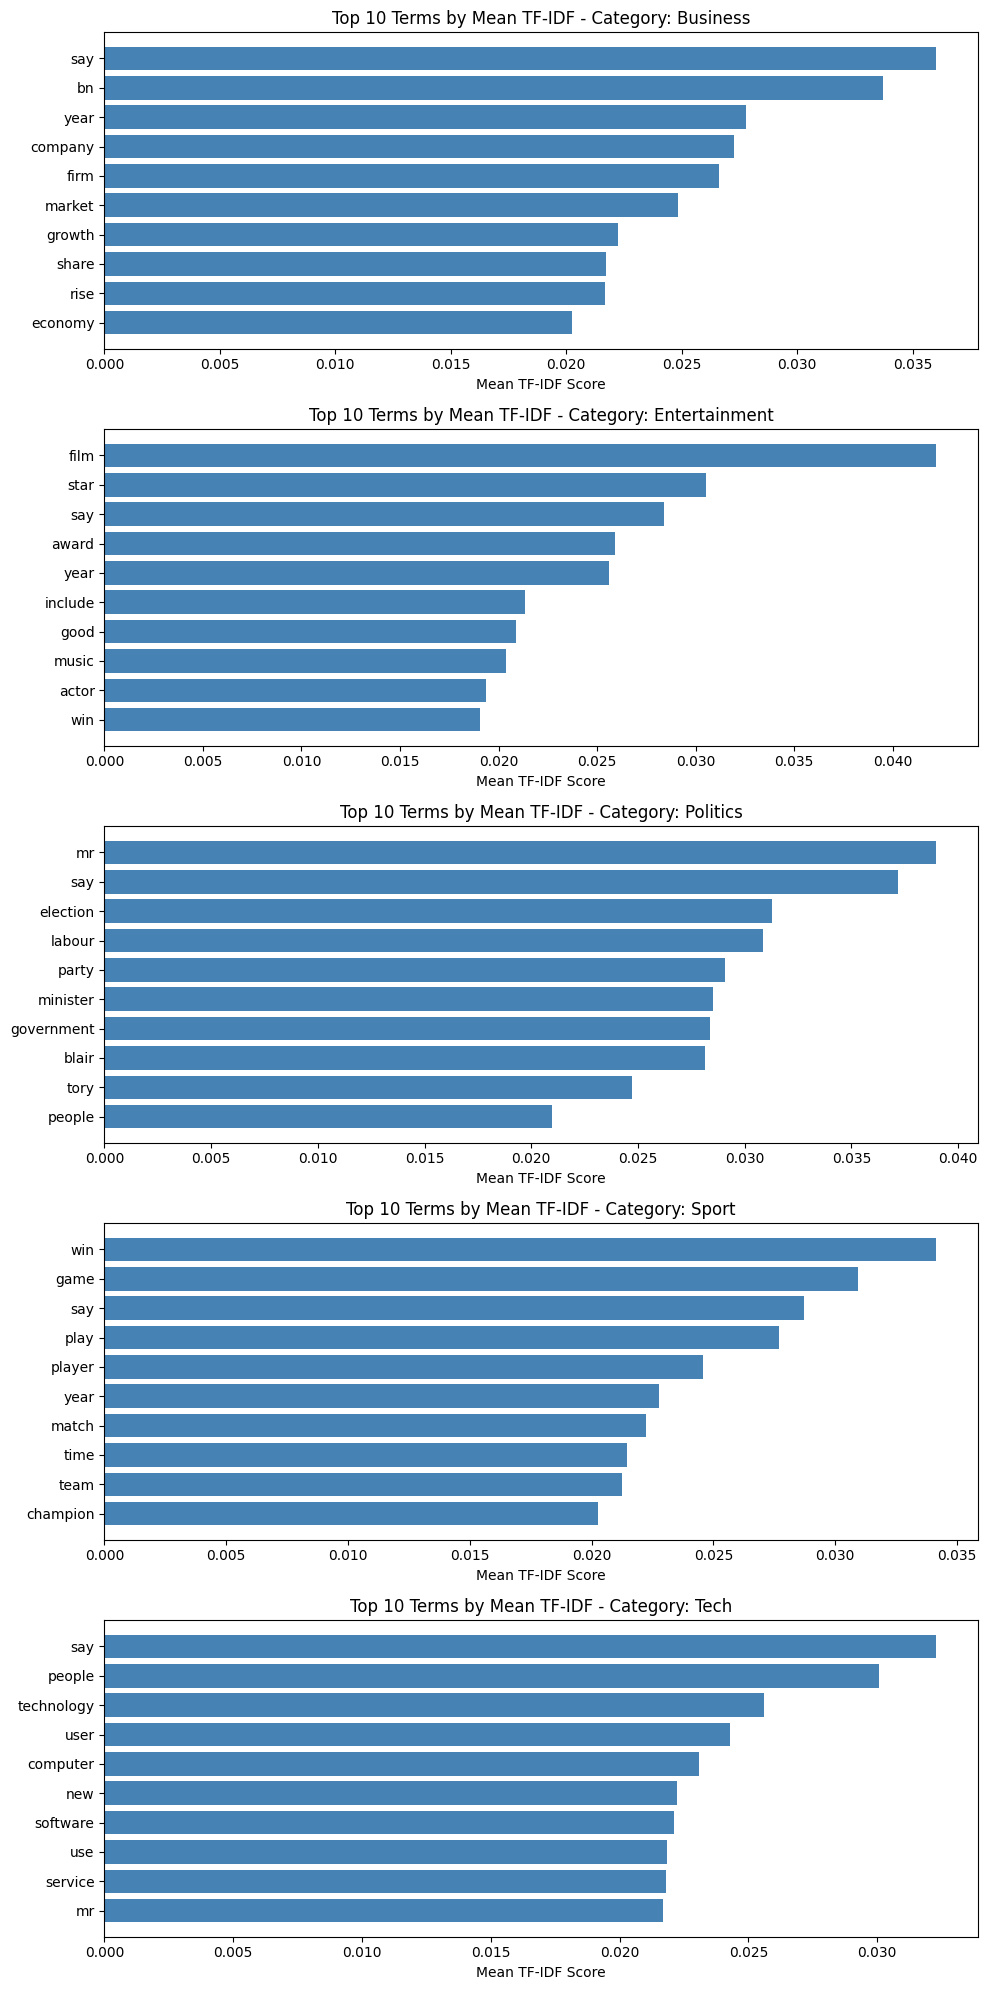

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    sublinear_tf=True,
    min_df=5,
    norm='l2',
    encoding='latin-1',
    ngram_range=(1, 2),
    stop_words='english'
)

features = tfidf.fit_transform(news_df['processed_text']).toarray()
labels = news_df['category']
feature_names = np.array(tfidf.get_feature_names_out())

print(f"TF-IDF Feature Matrix Shape: {features.shape}")
print(f"Total vocabulary size: {len(feature_names)}")


from sklearn.feature_selection import chi2

N = 5  # Number of top terms to display per category
print("\n--- Top Correlated Terms Per Category ---")

for category in sorted(news_df['category'].unique()):
    category_mask = (labels == category)
    chi2_scores, _ = chi2(features, category_mask)
    indices = np.argsort(chi2_scores)[::-1]

    top_terms = feature_names[indices[:N]]
    print(f"\nCategory: {category.upper()}")
    print(", ".join(top_terms))

category_names = sorted(news_df['category'].unique())
fig, axes = plt.subplots(nrows=len(category_names), ncols=1, figsize=(10, 4 * len(category_names)))

# Reset index of news_df temporarily to make sure indices align perfectly with the feature matrix
news_df_reset = news_df.reset_index(drop=True)

for idx, cat in enumerate(category_names):
    cat_indices = news_df_reset[news_df_reset['category'] == cat].index
    cat_tfidf_mean = features[cat_indices].mean(axis=0)
    top_indices = np.argsort(cat_tfidf_mean)[::-1][:10]

    top_words = feature_names[top_indices]
    top_scores = cat_tfidf_mean[top_indices]

    axes[idx].barh(top_words[::-1], top_scores[::-1], color='steelblue')
    axes[idx].set_title(f"Top 10 Terms by Mean TF-IDF - Category: {cat.title()}")
    axes[idx].set_xlabel("Mean TF-IDF Score")

plt.tight_layout()
plt.show()

Extracting POS features: 100%|██████████| 2198/2198 [01:29<00:00, 24.66it/s]



--- Mean POS Counts per Category ---
               noun_count  noun_count  ...  adv_count  adv_count
category                               ...                      
business        79.612245   82.530093  ...   4.298469   4.125000
entertainment   91.845697   80.856383  ...   5.501484   4.308511
politics        91.166667   95.561358  ...   5.192982   5.454308
sport           89.674938   68.511312  ...   5.002481   4.414027
tech            85.115854  114.972752  ...   4.545732   6.422343

[5 rows x 8 columns]


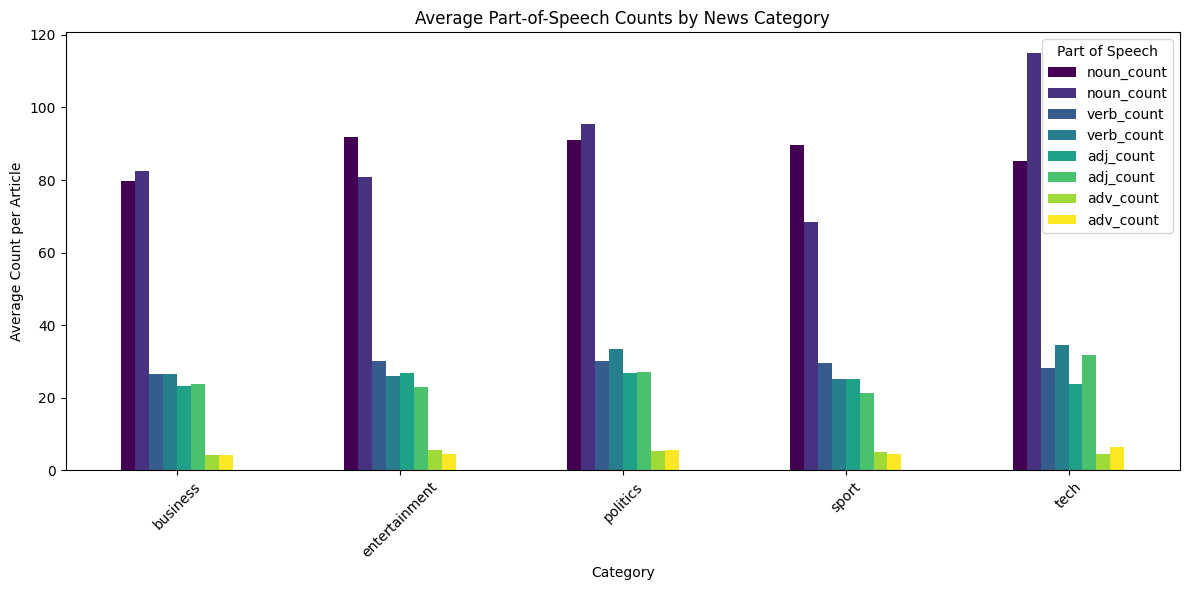

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from tqdm import tqdm

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    print("Downloading spaCy model...")
    import subprocess
    subprocess.run("python -m spacy download en_core_web_sm".split())
    nlp = spacy.load("en_core_web_sm")

def extract_pos_counts(text):
    # Ensure the input is a valid string
    if not isinstance(text, str):
        return {
            'noun_count': 0,
            'verb_count': 0,
            'adj_count': 0,
            'adv_count': 0
        }
    doc = nlp(text)
    counts = {
        'noun_count': len([token for token in doc if token.pos_ == 'NOUN']),
        'verb_count': len([token for token in doc if token.pos_ == 'VERB']),
        'adj_count': len([token for token in doc if token.pos_ == 'ADJ']),
        'adv_count': len([token for token in doc if token.pos_ == 'ADV'])
    }
    return counts

tqdm.pandas(desc="Extracting POS features")

pos_features = news_df['processed_text'].progress_apply(extract_pos_counts)
pos_df = pd.DataFrame(pos_features.tolist())

# Ensure indices align perfectly before concatenating
news_df_reset = news_df.reset_index(drop=True)
news_df = pd.concat([news_df_reset, pos_df], axis=1)

# Group by lowercase 'category'
category_pos_means = news_df.groupby('category')[['noun_count', 'verb_count', 'adj_count', 'adv_count']].mean()

print("\n--- Mean POS Counts per Category ---")
print(category_pos_means)

category_pos_means.plot(kind='bar', figsize=(12, 6), colormap='viridis')
plt.title('Average Part-of-Speech Counts by News Category')
plt.ylabel('Average Count per Article')
plt.xlabel('Category')
plt.xticks(rotation=45)
plt.legend(title='Part of Speech')
plt.tight_layout()
plt.show()

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Extracting syntactic structures (Module 5)...


Parsing Syntax: 100%|██████████| 2198/2198 [01:03<00:00, 34.49it/s] 



Extracting sentiment and emotional tone (Module 6)...


Analyzing Sentiment: 100%|██████████| 2198/2198 [00:05<00:00, 369.83it/s]
/tmp/ipykernel_2503/4241377017.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='category', y='compound_sentiment', data=news_df, palette='Set2')


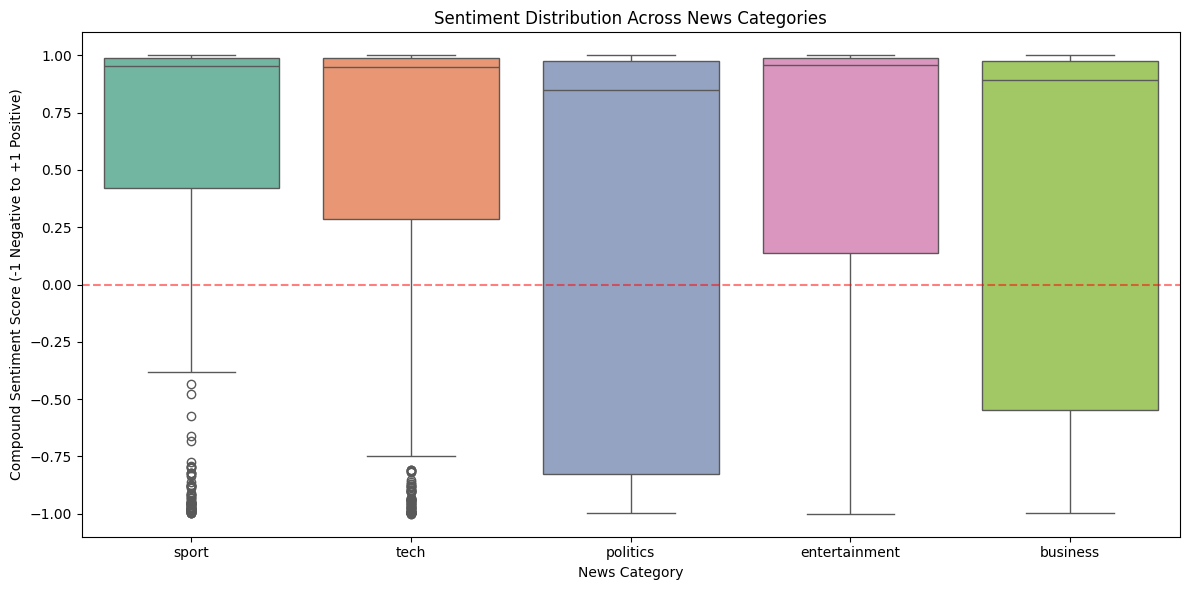


--- Emotional Tone Breakdown by Category (%) ---
emotional_tone  Negative  Neutral  Positive
category                                   
business           30.32     0.93     68.75
entertainment      23.14     0.80     76.06
politics           35.25     1.31     63.45
sport              19.68     0.90     79.41
tech               23.16     0.82     76.02


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
from tqdm import tqdm

nltk.download('vader_lexicon')
sia = SentimentIntensityAnalyzer()

def extract_semantic_roles(text):
    """Module 5: Dependency parsing and syntactic feature engineering."""
    # Ensure the input is a valid string
    text_str = str(text) if isinstance(text, str) else ""
    # To save computational time, we'll parse the first 1000 characters of each article
    doc = nlp(text_str[:1000])

    # Extract structural relationship counts
    subjects = len([token for token in doc if token.dep_ in ("nsubj", "nsubjpass")])
    objects = len([token for token in doc if token.dep_ in ("dobj", "pobj")])

    return pd.Series({'subject_count': subjects, 'object_count': objects})

print("Extracting syntactic structures (Module 5)...")
tqdm.pandas(desc="Parsing Syntax")
syntax_features = news_df['processed_text'].progress_apply(extract_semantic_roles)
news_df = pd.concat([news_df, syntax_features], axis=1)

def extract_sentiment(text):
    """Module 6: Article-level sentiment classification."""
    # Ensure the input is a valid string
    text_str = str(text) if isinstance(text, str) else ""
    # VADER returns a dictionary with 'neg', 'neu', 'pos', and a 'compound' score (-1 to 1)
    scores = sia.polarity_scores(text_str)

    # Categorize the compound score into an emotional tone
    tone = "Neutral"
    if scores['compound'] >= 0.05:
        tone = "Positive"
    elif scores['compound'] <= -0.05:
        tone = "Negative"

    return pd.Series({'compound_sentiment': scores['compound'], 'emotional_tone': tone})

print("\nExtracting sentiment and emotional tone (Module 6)...")
tqdm.pandas(desc="Analyzing Sentiment")
sentiment_features = news_df['processed_text'].progress_apply(extract_sentiment)
news_df = pd.concat([news_df, sentiment_features], axis=1)

plt.figure(figsize=(12, 6))
sns.boxplot(x='category', y='compound_sentiment', data=news_df, palette='Set2')
plt.title('Sentiment Distribution Across News Categories')
plt.xlabel('News Category')
plt.ylabel('Compound Sentiment Score (-1 Negative to +1 Positive)')
plt.axhline(0, color='red', linestyle='--', alpha=0.5) # Neutral line
plt.tight_layout()
plt.show()

sentiment_breakdown = pd.crosstab(news_df['category'], news_df['emotional_tone'], normalize='index') * 100
print("\n--- Emotional Tone Breakdown by Category (%) ---")
print(sentiment_breakdown.round(2))

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.2, random_state=42, stratify=labels
)

print(f"Training on {X_train.shape[0]} articles, Testing on {X_test.shape[0]} articles.\n")

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():
    print(f"Training {name}...")
    # Train the algorithm
    model.fit(X_train, y_train)

    # Make predictions on the unseen test data
    predictions = model.predict(X_test)

    # Calculate accuracy
    acc = accuracy_score(y_test, predictions)
    results.append({"Model": name, "Accuracy": acc})

    # Print the detailed classification report for each category
    print(f"\n--- {name} Performance ---")
    print(classification_report(y_test, predictions))
    print("-" * 50 + "\n")

results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False)
print("=== Final Model Comparison ===")
print(results_df.to_string(index=False))

Training on 1600 articles, Testing on 400 articles.

Training Naive Bayes...

--- Naive Bayes Performance ---
               precision    recall  f1-score   support

     business       0.71      0.76      0.73        86
entertainment       0.72      0.67      0.69        75
     politics       0.67      0.70      0.68        77
        sport       0.67      0.68      0.68        88
         tech       0.69      0.65      0.67        74

     accuracy                           0.69       400
    macro avg       0.69      0.69      0.69       400
 weighted avg       0.69      0.69      0.69       400

--------------------------------------------------

Training Logistic Regression...

--- Logistic Regression Performance ---
               precision    recall  f1-score   support

     business       0.71      0.76      0.73        86
entertainment       0.73      0.71      0.72        75
     politics       0.67      0.70      0.68        77
        sport       0.67      0.68      0.68  

Extracting named entities (Module 8)...


Extracting Entities: 100%|██████████| 2198/2198 [02:02<00:00, 17.98it/s] 



--- Top Most Frequent Entities Overall ---

DATE:
  • 2004: 285 occurrences
  • last year: 231 occurrences
  • 2005: 217 occurrences
  • this year: 190 occurrences
  • 2003: 174 occurrences

GPE:
  • us: 526 occurrences
  • uk: 467 occurrences
  • london: 270 occurrences
  • britain: 242 occurrences
  • france: 227 occurrences

MONEY:
  • million dollar: 24 occurrences
  • 50 cent: 20 occurrences
  • 1bn: 18 occurrences
  • 100: 14 occurrences
  • 1.8bn: 13 occurrences

ORG:
  • bbc: 247 occurrences
  • microsoft: 116 occurrences
  • sony: 104 occurrences
  • gm: 56 occurrences
  • the bbc news: 53 occurrences

PERSON:
  • nan: 198 occurrences
  • blair: 150 occurrences
  • tony blair: 97 occurrences
  • eu: 89 occurrences
  • gordon brown: 73 occurrences

--- Total Entity Counts by Category ---
                GPE  PERSON  DATE   ORG  MONEY
category                                      
business       1341    1079  2262  1226    756
entertainment   887    1762  1756   781    485
poli

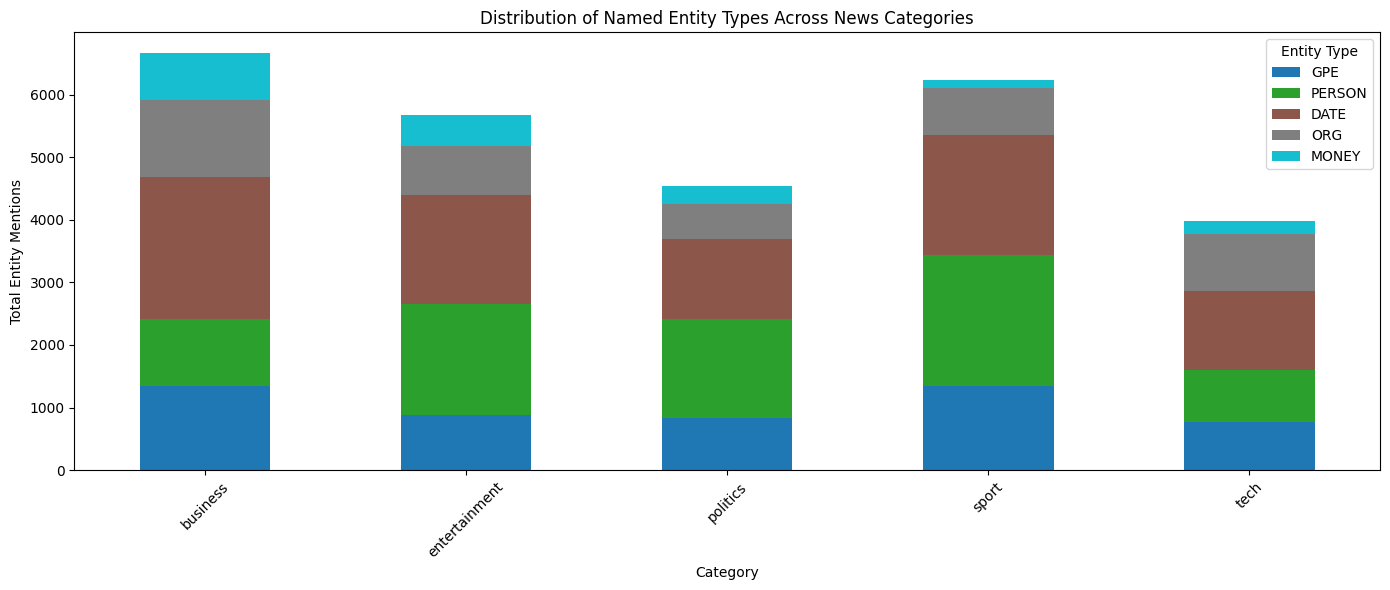

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from tqdm import tqdm

TARGET_LABELS = {'PERSON', 'ORG', 'GPE', 'DATE', 'MONEY'}

def extract_named_entities(raw_text):
    """Module 8: Extract targeted entity types using raw text."""
    # Use raw text (content column) rather than preprocessed text so capitalization/context remain intact
    doc = nlp(str(raw_text)[:1500])  # Process up to 1500 characters per article for Colab efficiency

    entities = {label: [] for label in TARGET_LABELS}
    for ent in doc.ents:
        if ent.label_ in TARGET_LABELS:
            entities[ent.label_].append(ent.text.strip())

    return pd.Series({
        'PERSON': entities['PERSON'],
        'ORG': entities['ORG'],
        'GPE': entities['GPE'],
        'DATE': entities['DATE'],
        'MONEY': entities['MONEY'],
        'total_entities': sum(len(lst) for lst in entities.values())
    })

print("Extracting named entities (Module 8)...")
tqdm.pandas(desc="Extracting Entities")
ner_df = news_df['content'].progress_apply(extract_named_entities)
news_df = pd.concat([news_df, ner_df], axis=1)

print("\n--- Top Most Frequent Entities Overall ---")
for label in sorted(TARGET_LABELS):
    all_ents = [ent for sublist in news_df[label] for ent in sublist]
    top_common = Counter(all_ents).most_common(5)
    print(f"\n{label}:")
    for name, count in top_common:
        print(f"  • {name}: {count} occurrences")

category_entity_counts = news_df.groupby('category')[list(TARGET_LABELS)].apply(
    lambda x: pd.Series({col: sum(len(lst) for lst in x[col]) for col in TARGET_LABELS})
)

print("\n--- Total Entity Counts by Category ---")
print(category_entity_counts)

category_entity_counts.plot(kind='bar', figsize=(14, 6), stacked=True, colormap='tab10')
plt.title('Distribution of Named Entity Types Across News Categories')
plt.xlabel('Category')
plt.ylabel('Total Entity Mentions')
plt.xticks(rotation=45)
plt.legend(title='Entity Type')
plt.tight_layout()
plt.show()